In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
import math
from IPython.display import Audio

def rk4_step(f, u, t, dt, *args):
    k1 = f(u, t, *args)
    k2 = f(u + 0.5*dt*k1, t + 0.5*dt, *args)
    k3 = f(u + 0.5*dt*k2, t + 0.5*dt, *args)
    k4 = f(u + dt*k3, t + dt, *args)
    return u + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)


sigma = 10.0
rho = 28.0
beta = 8.0/3.0
def lorenz(u, t, sigma=sigma, rho=rho, beta=beta):
    x, y, z = u
    return np.array([sigma*(y - x),
                     x*(rho - z) - y,
                     x*y - beta*z], dtype=float)

def jacobian_lorenz_single(u, sigma=sigma, rho=rho, beta=beta):
    x, y, z = u
    return np.array([
        [-sigma,      sigma,      0.0],
        [rho - z,     -1.0,      -x  ],
        [y,           x,        -beta]
    ], dtype=float)


def jacobian_error_sync(tx_state, k,
                        sigma=sigma, rho=rho, beta=beta):
    """
    Transverse Jacobian evaluated on the synchronized trajectory.
    Used only for the unforced system m(t)=0.
    """
    x1, y1, z1 = tx_state

    return np.array([
        [-(sigma + k), sigma, 0.0],
        [rho - z1, -1.0, -x1],
        [y1, x1, -beta]
    ], dtype=float)


In [ ]:
def load_multiple_speechcommands_messages(
        label=None,
        num_samples=20,
    ):
    """
    Load normalized one-second Speech Commands samples.

    Returns:
    audios : list[np.ndarray]
        Audio waveforms sampled at 16 kHz.
    labels : list[str]
        Corresponding command labels.
    sr : int
        Sampling rate.
    """
    ds, info = tfds.load(
        "speech_commands",
        split="train",
        with_info=True,
        shuffle_files=False,
    )

    sr = info.features["audio"].sample_rate
    excluded_labels = {"_unknown_", "_silence_"}

    audios = []
    labels = []

    for ex in ds:
        lab = info.features["label"].int2str(
            ex["label"].numpy()
        )

        if lab in excluded_labels:
            continue

        if label is not None and lab != label:
            continue

        audio = ex["audio"].numpy().astype(np.float32)

        peak = np.max(np.abs(audio))
        if peak < 1e-12:
            continue

        audio = audio / peak

        # Ensure a fixed one-second duration.
        if len(audio) < sr:
            audio = np.pad(audio, (0, sr - len(audio)))
        else:
            audio = audio[:sr]

        audios.append(audio.astype(np.float32))
        labels.append(lab)

        if len(audios) >= num_samples:
            break

    if not audios:
        raise RuntimeError("No matching audio samples were found.")

    return audios, labels, sr

k = 0.00, largest conditional LE = 0.9592
k = 2.50, largest conditional LE = 0.6368
k = 5.00, largest conditional LE = 0.3180
k = 7.50, largest conditional LE = 0.0356
k = 10.00, largest conditional LE = -0.2148
k = 12.50, largest conditional LE = -0.4183
k = 15.00, largest conditional LE = -0.5466
k = 17.50, largest conditional LE = -0.6731
k = 20.00, largest conditional LE = -0.7902
k = 22.50, largest conditional LE = -0.9045
k = 25.00, largest conditional LE = -1.0322
k = 27.50, largest conditional LE = -1.0597
k = 30.00, largest conditional LE = -1.1161
k = 32.50, largest conditional LE = -1.1729
k = 35.00, largest conditional LE = -1.2220
k = 37.50, largest conditional LE = -1.2595
k = 40.00, largest conditional LE = -1.2925
k = 42.50, largest conditional LE = -1.3247
k = 45.00, largest conditional LE = -1.3569
k = 47.50, largest conditional LE = -1.3898
k = 50.00, largest conditional LE = -1.4041
Estimated zero crossing: k_c ≈ 7.86
Initial synchronization error: 11.83691260422243

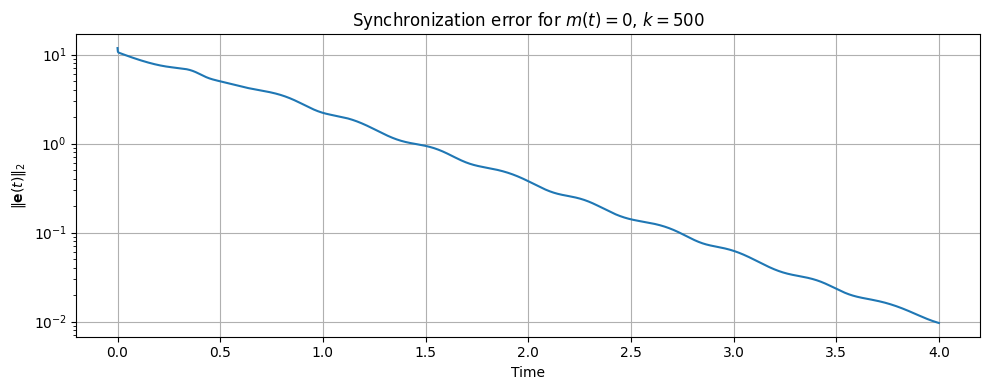

In [ ]:
def simulate_tx(u0_tx, t_steps, dt):
    traj = np.zeros((t_steps, 3), dtype=float)
    u = u0_tx.copy().astype(float)
    t = 0.0
    for i in range(t_steps):
        traj[i] = u.copy()
        u = rk4_step(lorenz, u, t, dt)
        t += dt
    return traj

def simulate_tx_rx_with_message(
        u0_tx,
        u0_rx,
        m_array,
        alpha,
        k,
        dt,
    ):
    N = len(m_array)

    tx = np.zeros((N, 3), dtype=float)
    rx = np.zeros((N, 3), dtype=float)
    s = np.zeros(N, dtype=float)

    u_tx = np.asarray(u0_tx, dtype=float).copy()
    u_rx = np.asarray(u0_rx, dtype=float).copy()

    t = 0.0

    for i in range(N):
        # Record states at the current time.
        tx[i] = u_tx
        rx[i] = u_rx

        s_t = u_tx[0] + alpha * m_array[i]
        s[i] = s_t

        def rx_rhs(u_local, t_local):
            x, y, z = u_local

            return np.array([
                sigma * (y - x) + k * (s_t - x),
                x * (rho - z) - y,
                x * y - beta * z,
            ], dtype=float)

        u_tx = rk4_step(lorenz, u_tx, t, dt)
        u_rx = rk4_step(rx_rhs, u_rx, t, dt)

        t += dt

    return tx, rx, s


def compute_cle_from_tx(
        tx_traj,
        k,
        dt,
        ortho_interval=100,
        t_transient=0.0,
    ):
    """
    Estimate conditional Lyapunov exponents of the homogeneous
    transverse system along the synchronized transmitter trajectory.
    """
    N = len(tx_traj)
    start_idx = int(np.ceil(t_transient / dt))

    if start_idx >= N - 1:
        raise ValueError("Transient duration is too long.")

    V = np.eye(3, dtype=float)
    le_accum = np.zeros(3, dtype=float)
    count = 0

    for i in range(start_idx, N - 1):
        tx_current = tx_traj[i]
        tx_next = tx_traj[i + 1]
        tx_mid = 0.5 * (tx_current + tx_next)

        J1 = jacobian_error_sync(tx_current, k)
        J2 = jacobian_error_sync(tx_mid, k)
        J4 = jacobian_error_sync(tx_next, k)

        K1 = J1 @ V
        K2 = J2 @ (V + 0.5 * dt * K1)
        K3 = J2 @ (V + 0.5 * dt * K2)
        K4 = J4 @ (V + dt * K3)

        V = V + (dt / 6.0) * (
            K1 + 2.0 * K2 + 2.0 * K3 + K4
        )

        step_count = i - start_idx + 1

        if step_count % ortho_interval == 0:
            Q, R = np.linalg.qr(V)

            diagonal = np.abs(np.diag(R))
            diagonal = np.maximum(diagonal, 1e-300)

            le_accum += np.log(diagonal)
            count += 1
            V = Q

    if count == 0:
        raise RuntimeError(
            "No QR orthonormalization was performed."
        )

    total_time = count * ortho_interval * dt
    lyapunov_exponents = le_accum / total_time

    return np.sort(lyapunov_exponents)[::-1]
dt_sweep = 0.001
T_sweep = 50.0
transient = 10.0

k_values = np.linspace(0.0, 50.0, 21)

u0_tx = np.array([0.1, 1.0, 1.05])

N_sweep = int(np.ceil(T_sweep / dt_sweep))
tx_traj = simulate_tx(u0_tx, N_sweep, dt_sweep)

max_lyaps = []

for k_val in k_values:
    lyaps = compute_cle_from_tx(
        tx_traj=tx_traj,
        k=k_val,
        dt=dt_sweep,
        ortho_interval=100,
        t_transient=transient,
    )

    lambda_max = lyaps[0]
    max_lyaps.append(lambda_max)

    print(
        f"k = {k_val:.2f}, "
        f"largest conditional LE = {lambda_max:.4f}"
    )

max_lyaps = np.asarray(max_lyaps)

kc_estimate = None

for i in range(len(k_values) - 1):
    left = max_lyaps[i]
    right = max_lyaps[i + 1]

    if left > 0.0 and right < 0.0:
        slope = (
            (right - left)
            / (k_values[i + 1] - k_values[i])
        )

        kc_estimate = (
            k_values[i] - left / slope
        )
        break

if kc_estimate is not None:
    print(f"Estimated zero crossing: k_c ≈ {kc_estimate:.2f}")
else:
    print("No zero crossing was found.")


u0_tx = np.array([0.1, 1.0, 1.05])
u0_rx = np.array([5.0, -5.0, 10.0])
dt_sync = 1.0 / 16000.0
T_sync = 4.0
N_sync = int(T_sync / dt_sync)

m_zero = np.zeros(N_sync, dtype=np.float32)

k_sync = 500
alpha_sync = 0.5  # irrelevant here because m(t) = 0

tx_zero, rx_zero, s_zero = simulate_tx_rx_with_message(
    u0_tx=u0_tx,
    u0_rx=u0_rx,
    m_array=m_zero,
    alpha=alpha_sync,
    k=k_sync,
    dt=dt_sync,
)

error_zero = tx_zero - rx_zero

error_norm = np.linalg.norm(
    error_zero,
    axis=1,
)

t_sync = np.arange(N_sync) * dt_sync

print(
    "Initial synchronization error:",
    error_norm[0],
)

print(
    "Final synchronization error:",
    error_norm[-1],
)


plt.figure(figsize=(10, 4))

plt.semilogy(
    t_sync,
    np.maximum(error_norm, 1e-15),
)

plt.xlabel("Time")
plt.ylabel(
    r"$\|\mathbf{e}(t)\|_2$"
)

plt.title(
    r"Synchronization error for $m(t)=0$, $k=500$"
)

plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\pjw10\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


C:\Users\pjw10\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Dl Completed...: 100%|██████████| 2/2 [02:34<00:00, 77.34s/ url]


Dataset speech_commands downloaded and prepared to C:\Users\pjw10\tensorflow_datasets\speech_commands\0.0.3. Subsequent calls will reuse this data.
Validation labels: ['off', 'on', 'stop', 'on', 'on']
Test labels: ['stop', 'off', 'left', 'stop', 'right', 'right', 'right', 'right', 'yes', 'go']

Validation results for alpha=0.10
  k= 50, mean validation correlation=0.0479
  k=100, mean validation correlation=0.1153
  k=200, mean validation correlation=0.2490
  k=300, mean validation correlation=0.3669
  k=500, mean validation correlation=0.5425
Selected k=500 for alpha=0.10

Validation results for alpha=0.50
  k= 50, mean validation correlation=0.2336
  k=100, mean validation correlation=0.4967
  k=200, mean validation correlation=0.7759
  k=300, mean validation correlation=0.8768
  k=500, mean validation correlation=0.9313
Selected k=500 for alpha=0.50

Testing alpha=0.10 with fixed k=500
 1. label=stop     corr= 0.5446 MSE=3.2646e-02 identity error=4.47e-08


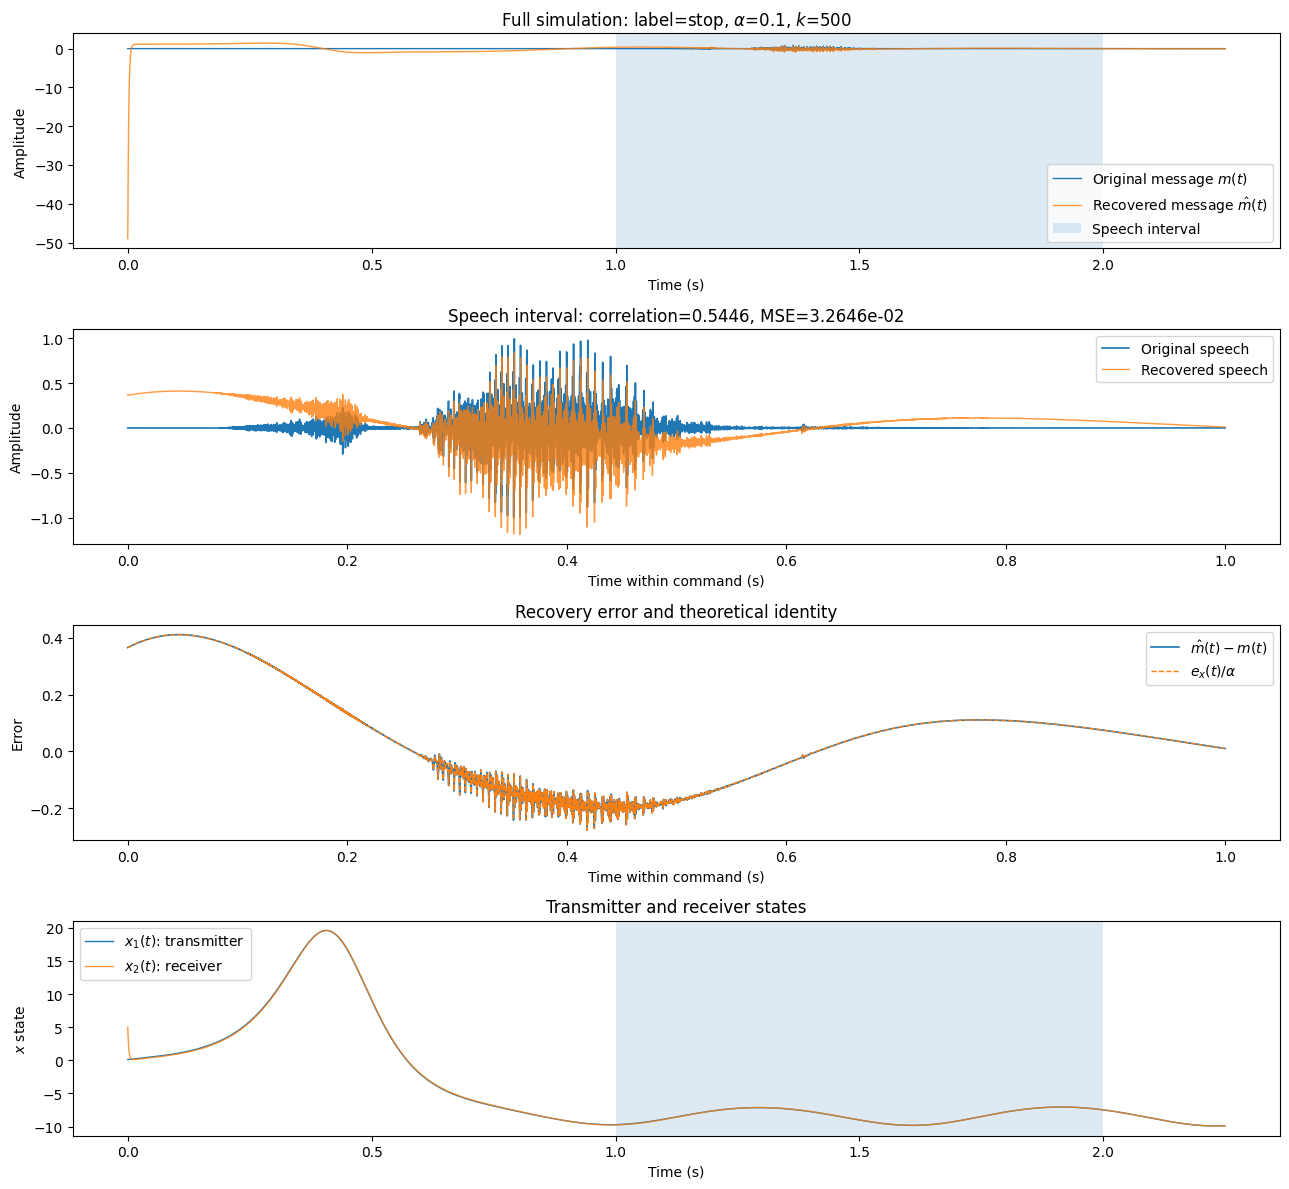


Original audio: stop


Recovered audio: stop, alpha=0.1, k=500


 2. label=off      corr= 0.6175 MSE=3.3263e-02 identity error=4.47e-08


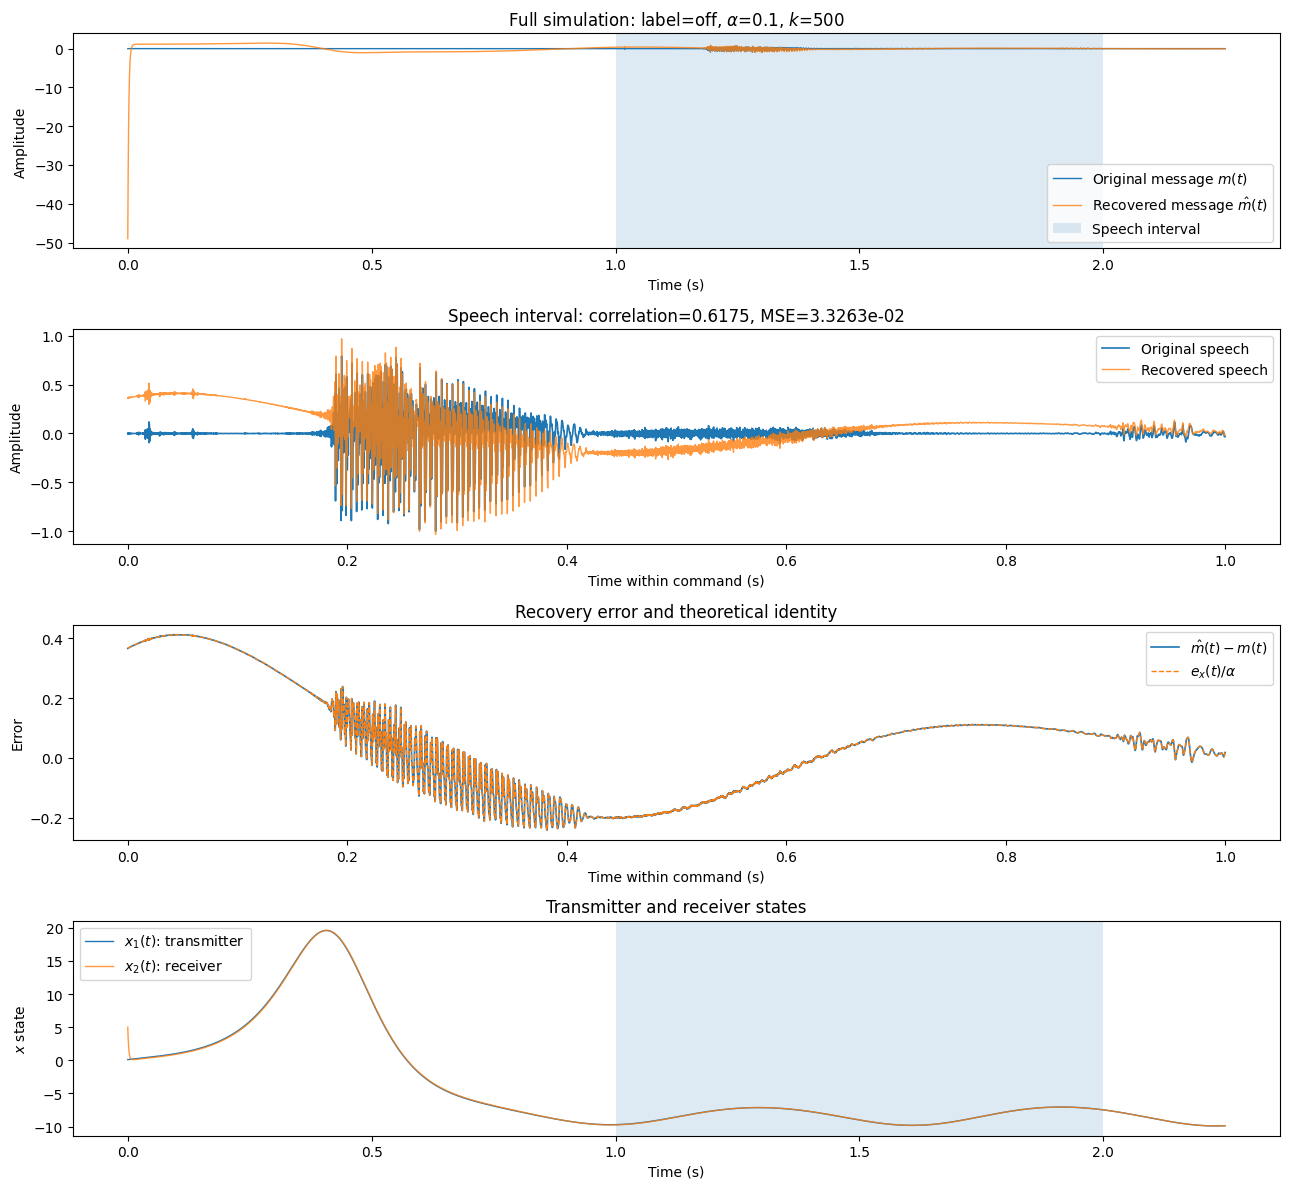

 3. label=left     corr= 0.4499 MSE=3.3606e-02 identity error=4.47e-08
 4. label=stop     corr= 0.5194 MSE=3.2869e-02 identity error=4.47e-08
 5. label=right    corr= 0.5948 MSE=3.3040e-02 identity error=4.47e-08
 6. label=right    corr= 0.4931 MSE=3.2791e-02 identity error=4.47e-08
 7. label=right    corr= 0.5565 MSE=3.3116e-02 identity error=4.47e-08
 8. label=right    corr= 0.4958 MSE=3.5144e-02 identity error=4.47e-08
 9. label=yes      corr= 0.2919 MSE=3.2602e-02 identity error=4.47e-08
10. label=go       corr= 0.8061 MSE=3.3626e-02 identity error=4.47e-08

Summary
alpha=0.10, k=500
Mean correlation = 0.5370 ± 0.1309
Mean MSE = 3.3270e-02 ± 7.4927e-04

Testing alpha=0.50 with fixed k=500
 1. label=stop     corr= 0.9524 MSE=1.4030e-03 identity error=1.78e-15


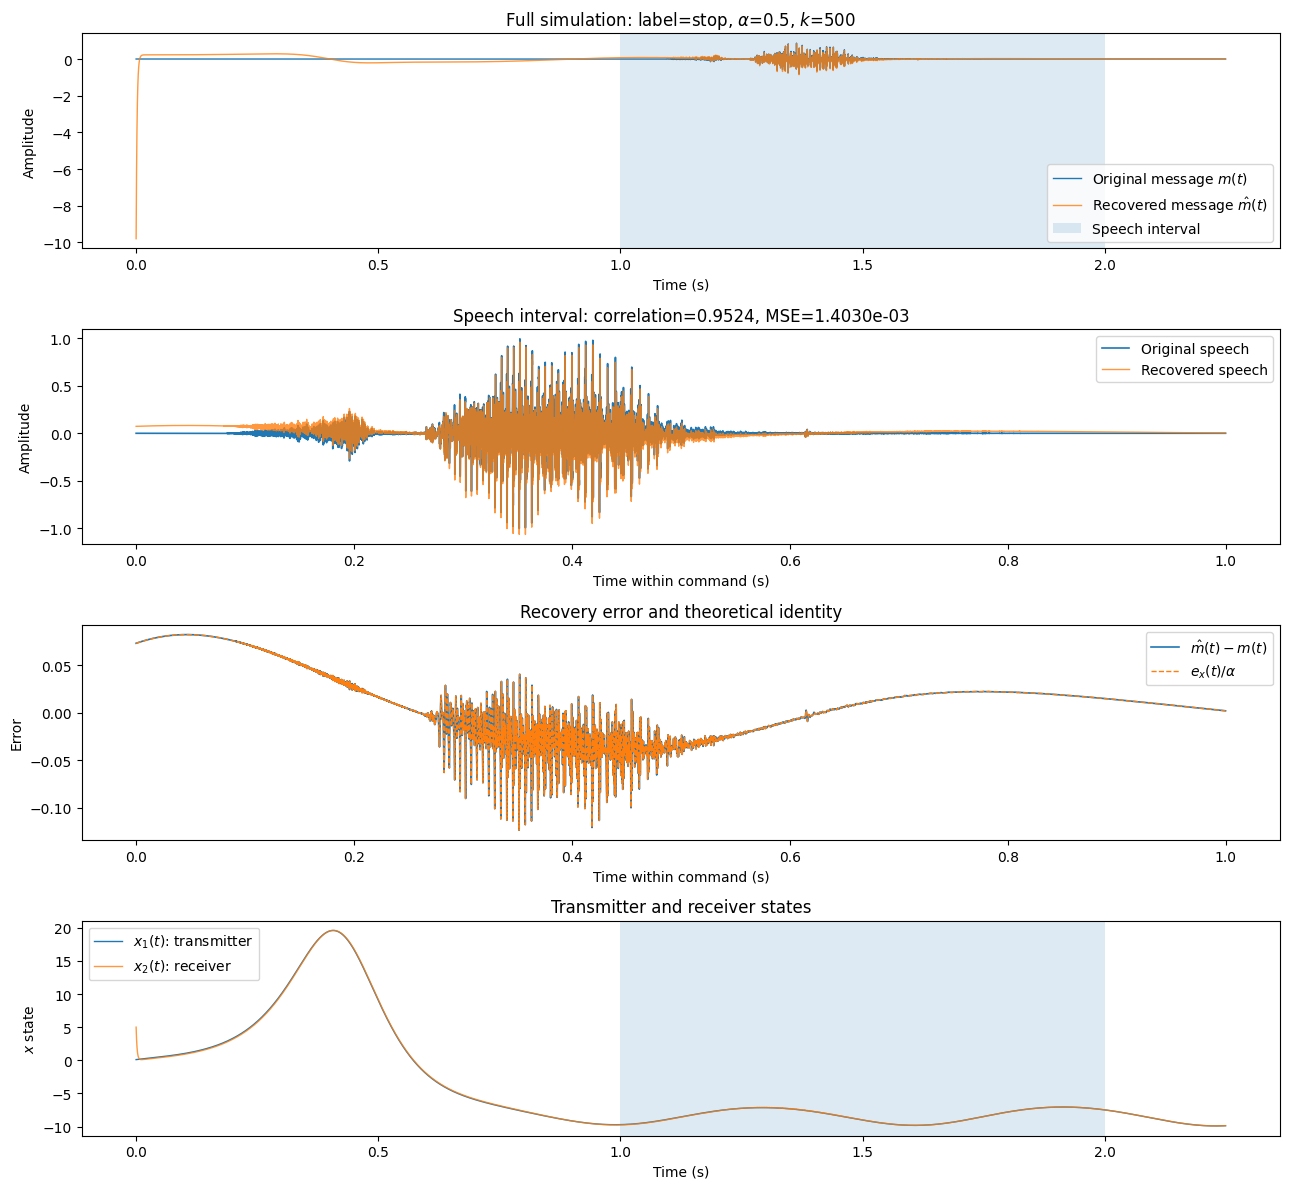


Original audio: stop


Recovered audio: stop, alpha=0.5, k=500


 2. label=off      corr= 0.9528 MSE=2.0348e-03 identity error=1.78e-15


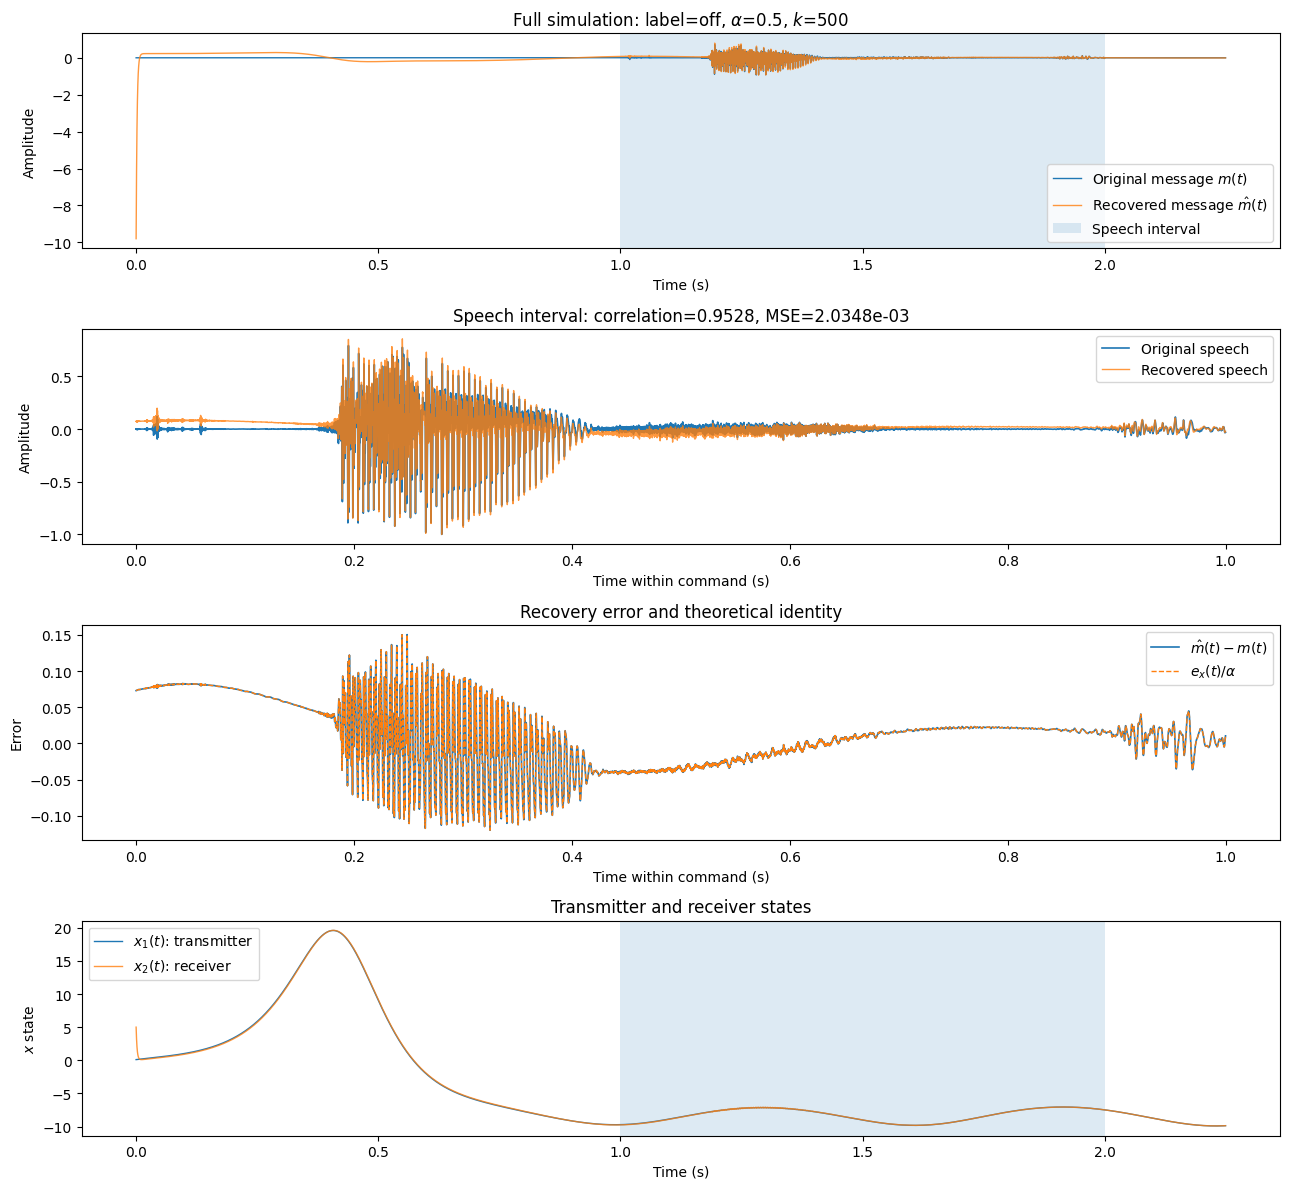

 3. label=left     corr= 0.8851 MSE=2.3727e-03 identity error=1.78e-15
 4. label=stop     corr= 0.9382 MSE=1.6301e-03 identity error=1.78e-15
 5. label=right    corr= 0.9528 MSE=1.8013e-03 identity error=1.78e-15
 6. label=right    corr= 0.9337 MSE=1.5343e-03 identity error=1.78e-15
 7. label=right    corr= 0.9416 MSE=1.8682e-03 identity error=1.78e-15
 8. label=right    corr= 0.8692 MSE=3.9267e-03 identity error=1.78e-15
 9. label=yes      corr= 0.8300 MSE=1.3638e-03 identity error=1.78e-15
10. label=go       corr= 0.9804 MSE=2.4362e-03 identity error=1.78e-15

Summary
alpha=0.50, k=500
Mean correlation = 0.9236 ± 0.0467
Mean MSE = 2.0371e-03 ± 7.6016e-04


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import soundfile as sf


def build_message_with_preamble(
        audio,
        sample_rate,
        preamble_duration=1.0,
        postamble_duration=0.25,
    ):
    preamble = np.zeros(
        int(preamble_duration * sample_rate),
        dtype=np.float32,
    )

    postamble = np.zeros(
        int(postamble_duration * sample_rate),
        dtype=np.float32,
    )

    message = np.concatenate([
        preamble,
        audio,
        postamble,
    ])

    speech_start = len(preamble)
    speech_end = speech_start + len(audio)
    speech_slice = slice(speech_start, speech_end)

    return message, speech_slice


def safe_correlation(a, b):
    """
    Compute Pearson correlation safely.
    """
    a = np.asarray(a)
    b = np.asarray(b)

    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return np.nan

    return float(np.corrcoef(a, b)[0, 1])


def normalize_for_audio(x):
    """
    Normalize only for audio playback or WAV export.
    Do not use this normalized array when calculating MSE.
    """
    x = np.nan_to_num(
        np.asarray(x, dtype=np.float32),
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    )

    peak = np.max(np.abs(x))

    if peak < 1e-12:
        return x

    return 0.95 * x / peak


raw_audios, raw_labels, sr = (
    load_multiple_speechcommands_messages(
        num_samples=20
    )
)

validation_audios = raw_audios[:5]
validation_labels = raw_labels[:5]

test_audios = raw_audios[5:15]
test_labels = raw_labels[5:15]

dt = 1.0 / sr

u0_tx = np.array([0.1, 1.0, 1.05])
u0_rx = np.array([5.0, -5.0, 10.0])

print("Validation labels:", validation_labels)
print("Test labels:", test_labels)

def evaluate_parameters(
        audios,
        alpha,
        k,
        sr,
        dt,
        u0_tx,
        u0_rx,
    ):
    correlations = []

    for audio in audios:
        message, speech_slice = build_message_with_preamble(
            audio,
            sample_rate=sr,
        )

        tx, rx, s = simulate_tx_rx_with_message(
            u0_tx=u0_tx,
            u0_rx=u0_rx,
            m_array=message,
            alpha=alpha,
            k=k,
            dt=dt,
        )

        x2 = rx[:, 0]
        m_hat = (s - x2) / alpha

        corr = safe_correlation(
            message[speech_slice],
            m_hat[speech_slice],
        )

        if not np.isnan(corr):
            correlations.append(corr)

    if not correlations:
        return -np.inf

    return float(np.mean(correlations))


alpha_values = [0.1, 0.5]
k_candidates = [50, 100, 200, 300, 500]

selected_k = {}

for alpha in alpha_values:
    mean_scores = {}

    print(f"\nValidation results for alpha={alpha:.2f}")

    for k in k_candidates:
        score = evaluate_parameters(
            audios=validation_audios,
            alpha=alpha,
            k=k,
            sr=sr,
            dt=dt,
            u0_tx=u0_tx,
            u0_rx=u0_rx,
        )

        mean_scores[k] = score

        print(
            f"  k={k:>3}, "
            f"mean validation correlation={score:.4f}"
        )

    selected_k[alpha] = max(
        mean_scores,
        key=mean_scores.get,
    )

    print(
        f"Selected k={selected_k[alpha]} "
        f"for alpha={alpha:.2f}"
    )


def plot_recovery_result(
        message,
        m_hat,
        tx,
        rx,
        speech_slice,
        sr,
        alpha,
        k,
        label,
        corr,
        mse,
    ):
    x1 = tx[:, 0]
    x2 = rx[:, 0]
    e_x = x1 - x2

    speech_start = speech_slice.start
    speech_end = speech_slice.stop

    t_speech = (
        np.arange(speech_end - speech_start) / sr
    )

    original_speech = message[speech_slice]
    recovered_speech = m_hat[speech_slice]

    recovery_error = (
        recovered_speech - original_speech
    )

    predicted_error = (
        e_x[speech_slice] / alpha
    )

    plot_stride = max(1, len(message) // 5000)
    full_indices = np.arange(
        0,
        len(message),
        plot_stride,
    )
    t_full = full_indices / sr

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(13, 12),
    )


    axes[0].plot(
        t_full,
        message[full_indices],
        label="Original message $m(t)$",
        linewidth=1,
    )

    axes[0].plot(
        t_full,
        m_hat[full_indices],
        label="Recovered message $\\hat{m}(t)$",
        linewidth=1,
        alpha=0.8,
    )

    axes[0].axvspan(
        speech_start / sr,
        speech_end / sr,
        alpha=0.15,
        label="Speech interval",
    )

    axes[0].set_title(
        f"Full simulation: label={label}, "
        f"$\\alpha$={alpha}, $k$={k}"
    )
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Amplitude")
    axes[0].legend()


    axes[1].plot(
        t_speech,
        original_speech,
        label="Original speech",
        linewidth=1.2,
    )

    axes[1].plot(
        t_speech,
        recovered_speech,
        label="Recovered speech",
        linewidth=1,
        alpha=0.8,
    )

    axes[1].set_title(
        f"Speech interval: correlation={corr:.4f}, "
        f"MSE={mse:.4e}"
    )
    axes[1].set_xlabel("Time within command (s)")
    axes[1].set_ylabel("Amplitude")
    axes[1].legend()


    axes[2].plot(
        t_speech,
        recovery_error,
        label="$\\hat{m}(t)-m(t)$",
        linewidth=1.2,
    )

    axes[2].plot(
        t_speech,
        predicted_error,
        linestyle="--",
        label="$e_x(t)/\\alpha$",
        linewidth=1,
    )

    axes[2].set_title(
        "Recovery error and theoretical identity"
    )
    axes[2].set_xlabel("Time within command (s)")
    axes[2].set_ylabel("Error")
    axes[2].legend()

    axes[3].plot(
        t_full,
        x1[full_indices],
        label="$x_1(t)$: transmitter",
        linewidth=1,
    )

    axes[3].plot(
        t_full,
        x2[full_indices],
        label="$x_2(t)$: receiver",
        linewidth=1,
        alpha=0.8,
    )

    axes[3].axvspan(
        speech_start / sr,
        speech_end / sr,
        alpha=0.15,
    )

    axes[3].set_title(
        "Transmitter and receiver states"
    )
    axes[3].set_xlabel("Time (s)")
    axes[3].set_ylabel("$x$ state")
    axes[3].legend()

    plt.tight_layout()
    plt.show()



results_log = []
max_plots_per_alpha = 2
play_first_sample = True

for alpha in alpha_values:
    k = selected_k[alpha]

    print("\n" + "=" * 70)
    print(
        f"Testing alpha={alpha:.2f} "
        f"with fixed k={k}"
    )
    print("=" * 70)

    alpha_results = []

    for sample_index, (audio, label) in enumerate(
        zip(test_audios, test_labels)
    ):
        message, speech_slice = build_message_with_preamble(
            audio,
            sample_rate=sr,
        )

        tx, rx, s = simulate_tx_rx_with_message(
            u0_tx=u0_tx,
            u0_rx=u0_rx,
            m_array=message,
            alpha=alpha,
            k=k,
            dt=dt,
        )

        x1 = tx[:, 0]
        x2 = rx[:, 0]

        e_x = x1 - x2
        m_hat = (s - x2) / alpha

        m_eval = message[speech_slice]
        m_hat_eval = m_hat[speech_slice]

        mse = float(
            np.mean(
                (m_hat_eval - m_eval) ** 2
            )
        )

        corr = safe_correlation(
            m_hat_eval,
            m_eval,
        )

        rmse = float(np.sqrt(mse))

        # This checks code/formula consistency only.
        identity_error = float(
            np.max(
                np.abs(
                    (m_hat - message)
                    - e_x / alpha
                )
            )
        )

        result = {
            "alpha": alpha,
            "k": k,
            "sample": sample_index + 1,
            "label": label,
            "corr": corr,
            "mse": mse,
            "rmse": rmse,
            "identity_error": identity_error,
        }

        alpha_results.append(result)
        results_log.append(result)

        print(
            f"{sample_index + 1:>2}. "
            f"label={label:<8} "
            f"corr={corr:>7.4f} "
            f"MSE={mse:.4e} "
            f"identity error={identity_error:.2e}"
        )

        # Plot representative samples.
        if sample_index < max_plots_per_alpha:
            plot_recovery_result(
                message=message,
                m_hat=m_hat,
                tx=tx,
                rx=rx,
                speech_slice=speech_slice,
                sr=sr,
                alpha=alpha,
                k=k,
                label=label,
                corr=corr,
                mse=mse,
            )

        # Directly listen to one original/recovered pair.
        if play_first_sample and sample_index == 0:
            print(f"\nOriginal audio: {label}")
            display(
                Audio(
                    normalize_for_audio(m_eval),
                    rate=sr,
                )
            )

            print(
                f"Recovered audio: {label}, "
                f"alpha={alpha}, k={k}"
            )
            display(
                Audio(
                    normalize_for_audio(m_hat_eval),
                    rate=sr,
                )
            )

            # Optional WAV export
            sf.write(
                f"original_{label}_alpha_{alpha}.wav",
                normalize_for_audio(m_eval),
                samplerate=sr,
            )

            sf.write(
                f"recovered_{label}_alpha_{alpha}.wav",
                normalize_for_audio(m_hat_eval),
                samplerate=sr,
            )

    valid_corrs = [
        result["corr"]
        for result in alpha_results
        if not np.isnan(result["corr"])
    ]

    mean_corr = float(np.mean(valid_corrs))
    std_corr = float(np.std(valid_corrs, ddof=1))

    mean_mse = float(
        np.mean([
            result["mse"]
            for result in alpha_results
        ])
    )

    std_mse = float(
        np.std(
            [
                result["mse"]
                for result in alpha_results
            ],
            ddof=1,
        )
    )

    print("\nSummary")
    print(
        f"alpha={alpha:.2f}, k={k}"
    )
    print(
        f"Mean correlation = "
        f"{mean_corr:.4f} ± {std_corr:.4f}"
    )
    print(
        f"Mean MSE = "
        f"{mean_mse:.4e} ± {std_mse:.4e}"
    )

C:\Users\pjw10\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


Validation labels: ['off', 'on', 'stop', 'on', 'on']
Test labels: ['stop', 'off', 'left', 'stop', 'right', 'right', 'right', 'right', 'yes', 'go']

Validation results for alpha=0.10
  k= 50, mean validation correlation=0.0112
  k=100, mean validation correlation=0.0214
  k=200, mean validation correlation=0.0371
  k=300, mean validation correlation=0.0487
  k=500, mean validation correlation=0.0654
Selected k=500 for alpha=0.10

Validation results for alpha=0.50
  k= 50, mean validation correlation=0.0532
  k=100, mean validation correlation=0.1040
  k=200, mean validation correlation=0.1802
  k=300, mean validation correlation=0.2345
  k=500, mean validation correlation=0.3080
Selected k=500 for alpha=0.50

Testing alpha=0.10 with fixed k=500
 1. label=stop     corr= 0.0635 MSE=3.1580e+00 identity error=4.47e-08


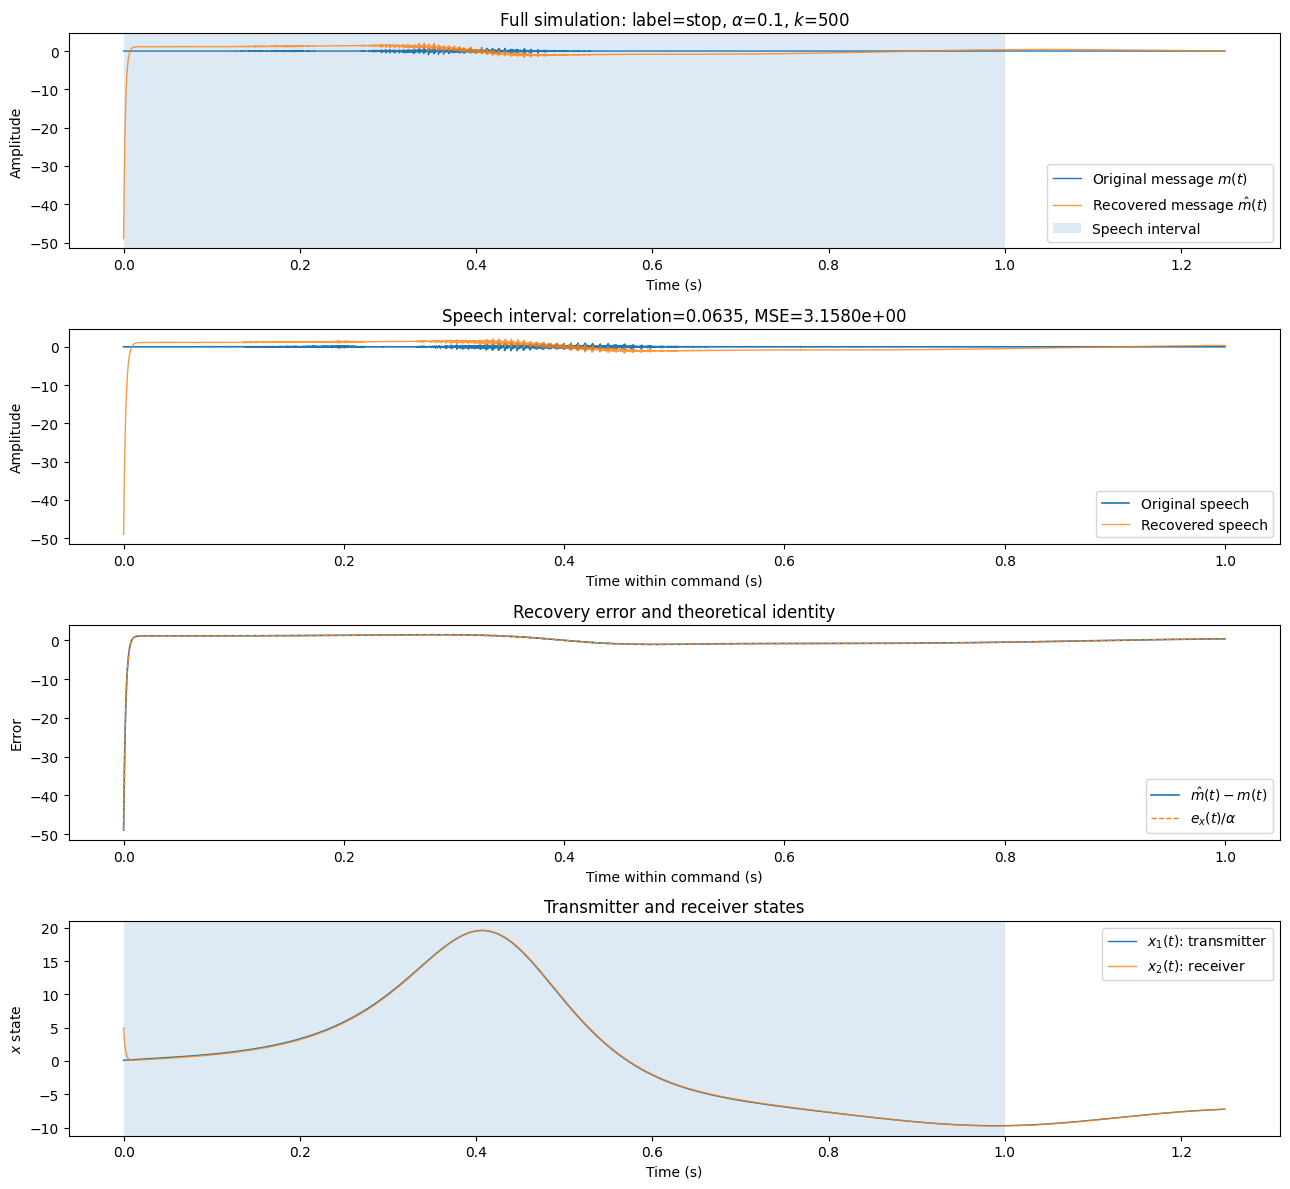


Original audio: stop


Recovered audio: stop, alpha=0.1, k=500


 2. label=off      corr= 0.0779 MSE=3.1584e+00 identity error=4.47e-08


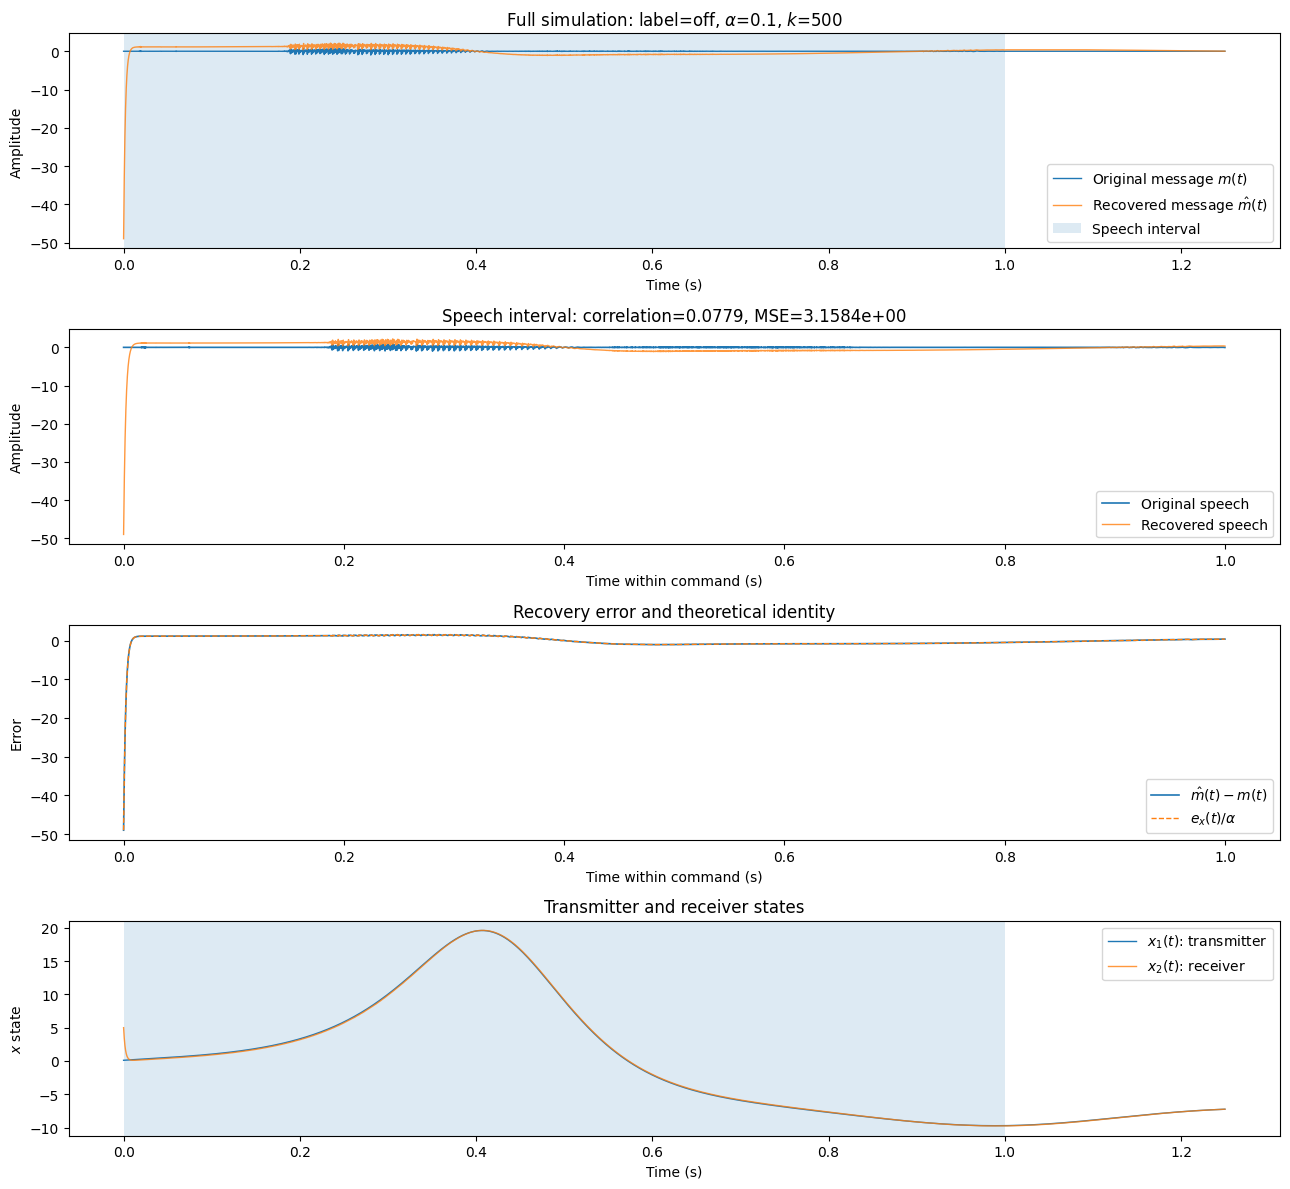

 3. label=left     corr= 0.0503 MSE=3.1588e+00 identity error=4.47e-08
 4. label=stop     corr= 0.0587 MSE=3.1584e+00 identity error=4.47e-08
 5. label=right    corr= 0.0728 MSE=3.1584e+00 identity error=4.47e-08
 6. label=right    corr= 0.0594 MSE=3.1575e+00 identity error=4.47e-08
 7. label=right    corr= 0.0646 MSE=3.1590e+00 identity error=4.47e-08
 8. label=right    corr= 0.1054 MSE=3.1497e+00 identity error=4.47e-08
 9. label=yes      corr= 0.0300 MSE=3.1579e+00 identity error=4.47e-08
10. label=go       corr= 0.1344 MSE=3.1587e+00 identity error=4.47e-08

Summary
alpha=0.10, k=500
Mean correlation = 0.0717 ± 0.0293
Mean MSE = 3.1575e+00 ± 2.7561e-03

Testing alpha=0.50 with fixed k=500
 1. label=stop     corr= 0.3031 MSE=1.2641e-01 identity error=3.55e-15


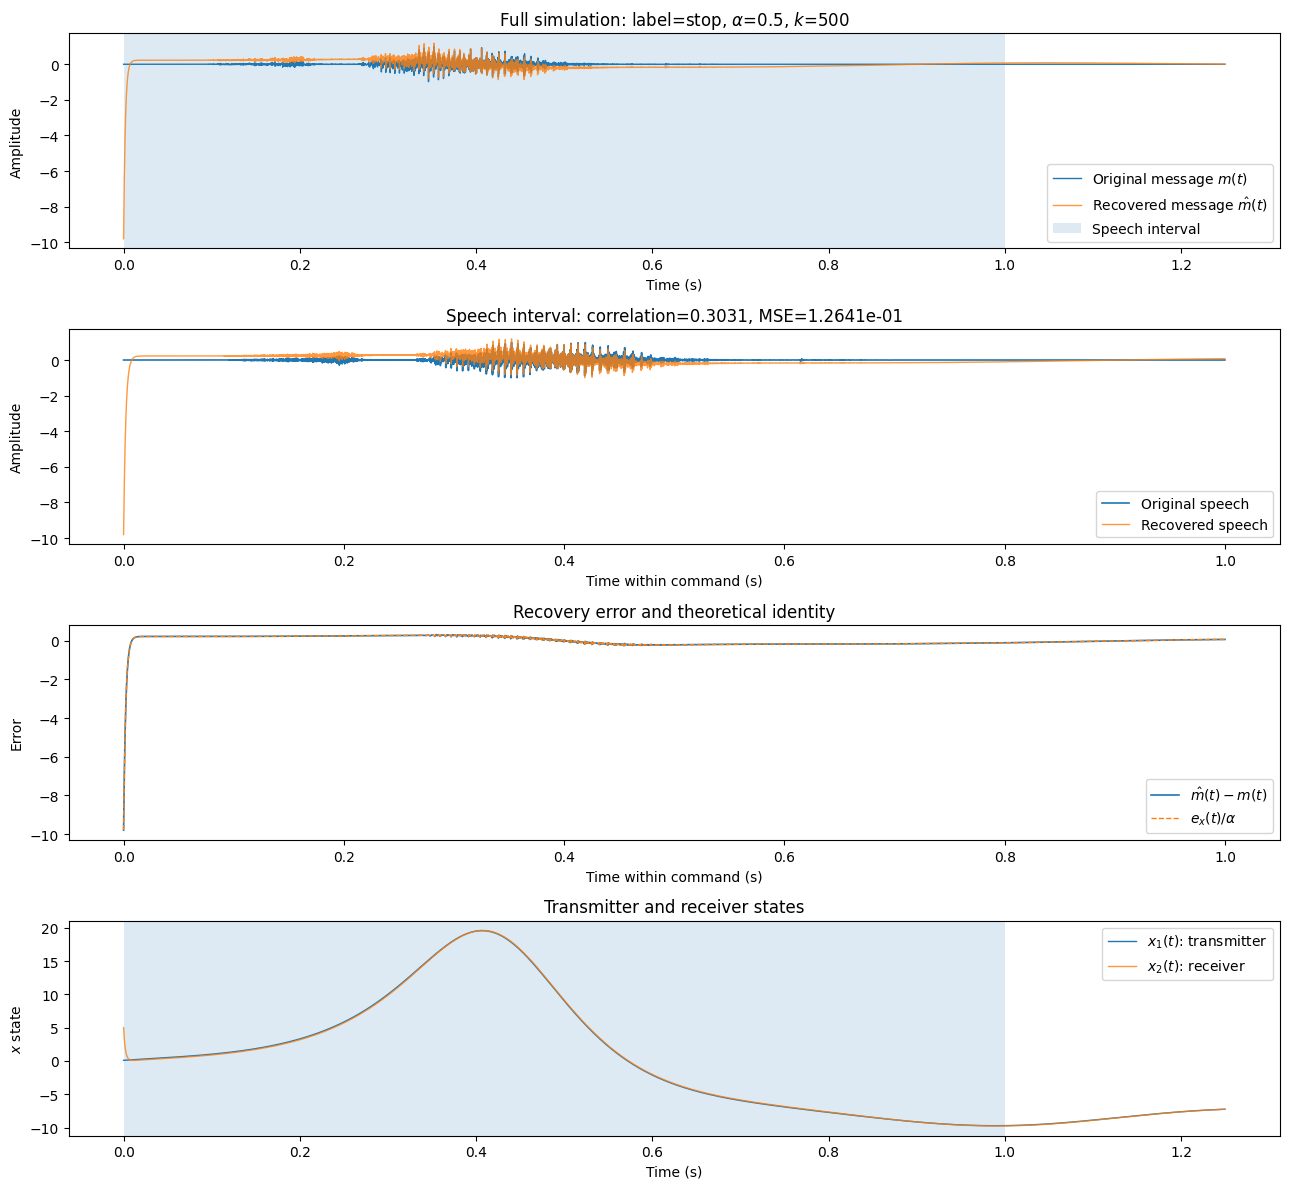


Original audio: stop


Recovered audio: stop, alpha=0.5, k=500


 2. label=off      corr= 0.3616 MSE=1.2701e-01 identity error=3.55e-15


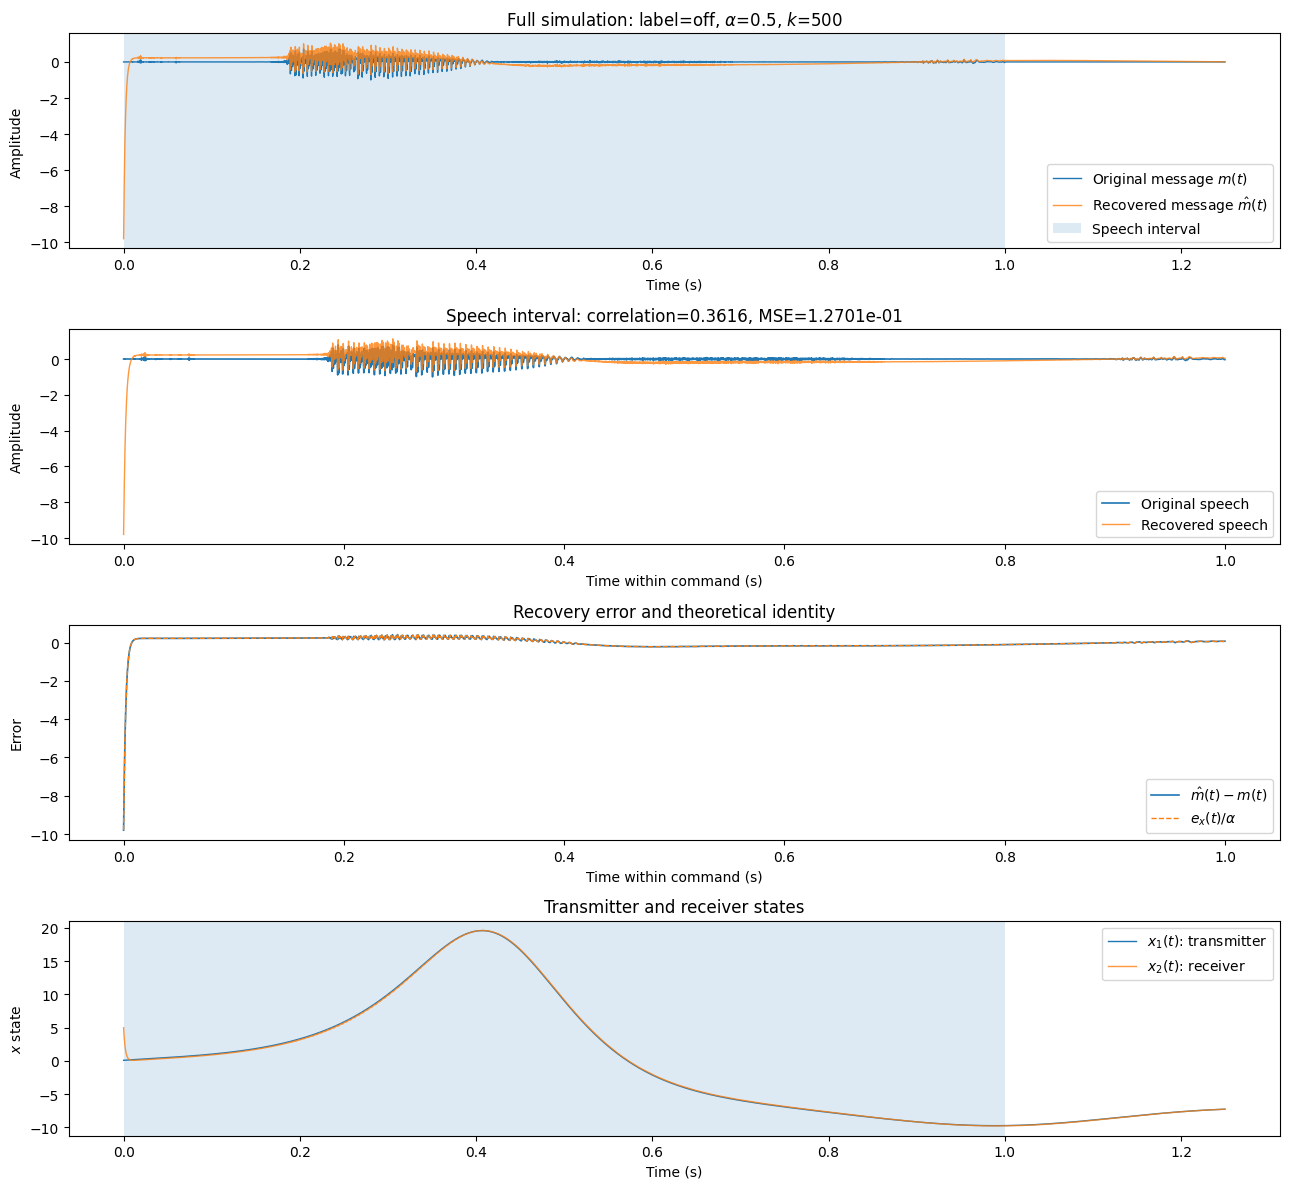

 3. label=left     corr= 0.2420 MSE=1.2736e-01 identity error=8.88e-16
 4. label=stop     corr= 0.2850 MSE=1.2668e-01 identity error=3.55e-15
 5. label=right    corr= 0.3420 MSE=1.2683e-01 identity error=3.55e-15
 6. label=right    corr= 0.2715 MSE=1.2642e-01 identity error=3.55e-15
 7. label=right    corr= 0.3119 MSE=1.2700e-01 identity error=3.55e-15
 8. label=right    corr= 0.3196 MSE=1.2680e-01 identity error=3.55e-15
 9. label=yes      corr= 0.1477 MSE=1.2637e-01 identity error=3.55e-15
10. label=go       corr= 0.5592 MSE=1.2741e-01 identity error=3.55e-15

Summary
alpha=0.50, k=500
Mean correlation = 0.3144 ± 0.1048
Mean MSE = 1.2683e-01 ± 3.7288e-04


In [ ]:
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import soundfile as sf


def build_message_with_preamble(
        audio,
        sample_rate,
        preamble_duration=0,
        postamble_duration=0.25,
    ):
    preamble = np.zeros(
        int(preamble_duration * sample_rate),
        dtype=np.float32,
    )

    postamble = np.zeros(
        int(postamble_duration * sample_rate),
        dtype=np.float32,
    )

    message = np.concatenate([
        preamble,
        audio,
        postamble,
    ])

    speech_start = len(preamble)
    speech_end = speech_start + len(audio)
    speech_slice = slice(speech_start, speech_end)

    return message, speech_slice


def safe_correlation(a, b):
    """
    Compute Pearson correlation safely.
    """
    a = np.asarray(a)
    b = np.asarray(b)

    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return np.nan

    return float(np.corrcoef(a, b)[0, 1])


def normalize_for_audio(x):
    """
    Normalize only for audio playback or WAV export.
    Do not use this normalized array when calculating MSE.
    """
    x = np.nan_to_num(
        np.asarray(x, dtype=np.float32),
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    )

    peak = np.max(np.abs(x))

    if peak < 1e-12:
        return x

    return 0.95 * x / peak


raw_audios, raw_labels, sr = (
    load_multiple_speechcommands_messages(
        num_samples=20
    )
)

validation_audios = raw_audios[:5]
validation_labels = raw_labels[:5]

test_audios = raw_audios[5:15]
test_labels = raw_labels[5:15]

dt = 1.0 / sr

u0_tx = np.array([0.1, 1.0, 1.05])
u0_rx = np.array([5.0, -5.0, 10.0])

print("Validation labels:", validation_labels)
print("Test labels:", test_labels)



def evaluate_parameters(
        audios,
        alpha,
        k,
        sr,
        dt,
        u0_tx,
        u0_rx,
    ):
    correlations = []

    for audio in audios:
        message, speech_slice = build_message_with_preamble(
            audio,
            sample_rate=sr,
        )

        tx, rx, s = simulate_tx_rx_with_message(
            u0_tx=u0_tx,
            u0_rx=u0_rx,
            m_array=message,
            alpha=alpha,
            k=k,
            dt=dt,
        )

        x2 = rx[:, 0]
        m_hat = (s - x2) / alpha

        corr = safe_correlation(
            message[speech_slice],
            m_hat[speech_slice],
        )

        if not np.isnan(corr):
            correlations.append(corr)

    if not correlations:
        return -np.inf

    return float(np.mean(correlations))


alpha_values = [0.1, 0.5]
k_candidates = [50, 100, 200, 300, 500]

selected_k = {}

for alpha in alpha_values:
    mean_scores = {}

    print(f"\nValidation results for alpha={alpha:.2f}")

    for k in k_candidates:
        score = evaluate_parameters(
            audios=validation_audios,
            alpha=alpha,
            k=k,
            sr=sr,
            dt=dt,
            u0_tx=u0_tx,
            u0_rx=u0_rx,
        )

        mean_scores[k] = score

        print(
            f"  k={k:>3}, "
            f"mean validation correlation={score:.4f}"
        )

    selected_k[alpha] = max(
        mean_scores,
        key=mean_scores.get,
    )

    print(
        f"Selected k={selected_k[alpha]} "
        f"for alpha={alpha:.2f}"
    )


def plot_recovery_result(
        message,
        m_hat,
        tx,
        rx,
        speech_slice,
        sr,
        alpha,
        k,
        label,
        corr,
        mse,
    ):
    x1 = tx[:, 0]
    x2 = rx[:, 0]
    e_x = x1 - x2

    speech_start = speech_slice.start
    speech_end = speech_slice.stop

    t_speech = (
        np.arange(speech_end - speech_start) / sr
    )

    original_speech = message[speech_slice]
    recovered_speech = m_hat[speech_slice]

    recovery_error = (
        recovered_speech - original_speech
    )

    predicted_error = (
        e_x[speech_slice] / alpha
    )

  
    plot_stride = max(1, len(message) // 5000)
    full_indices = np.arange(
        0,
        len(message),
        plot_stride,
    )
    t_full = full_indices / sr

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(13, 12),
    )


    axes[0].plot(
        t_full,
        message[full_indices],
        label="Original message $m(t)$",
        linewidth=1,
    )

    axes[0].plot(
        t_full,
        m_hat[full_indices],
        label="Recovered message $\\hat{m}(t)$",
        linewidth=1,
        alpha=0.8,
    )

    axes[0].axvspan(
        speech_start / sr,
        speech_end / sr,
        alpha=0.15,
        label="Speech interval",
    )

    axes[0].set_title(
        f"Full simulation: label={label}, "
        f"$\\alpha$={alpha}, $k$={k}"
    )
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Amplitude")
    axes[0].legend()

    axes[1].plot(
        t_speech,
        original_speech,
        label="Original speech",
        linewidth=1.2,
    )

    axes[1].plot(
        t_speech,
        recovered_speech,
        label="Recovered speech",
        linewidth=1,
        alpha=0.8,
    )

    axes[1].set_title(
        f"Speech interval: correlation={corr:.4f}, "
        f"MSE={mse:.4e}"
    )
    axes[1].set_xlabel("Time within command (s)")
    axes[1].set_ylabel("Amplitude")
    axes[1].legend()

    axes[2].plot(
        t_speech,
        recovery_error,
        label="$\\hat{m}(t)-m(t)$",
        linewidth=1.2,
    )

    axes[2].plot(
        t_speech,
        predicted_error,
        linestyle="--",
        label="$e_x(t)/\\alpha$",
        linewidth=1,
    )

    axes[2].set_title(
        "Recovery error and theoretical identity"
    )
    axes[2].set_xlabel("Time within command (s)")
    axes[2].set_ylabel("Error")
    axes[2].legend()

    axes[3].plot(
        t_full,
        x1[full_indices],
        label="$x_1(t)$: transmitter",
        linewidth=1,
    )

    axes[3].plot(
        t_full,
        x2[full_indices],
        label="$x_2(t)$: receiver",
        linewidth=1,
        alpha=0.8,
    )

    axes[3].axvspan(
        speech_start / sr,
        speech_end / sr,
        alpha=0.15,
    )

    axes[3].set_title(
        "Transmitter and receiver states"
    )
    axes[3].set_xlabel("Time (s)")
    axes[3].set_ylabel("$x$ state")
    axes[3].legend()

    plt.tight_layout()
    plt.show()


results_log = []
max_plots_per_alpha = 2
play_first_sample = True

for alpha in alpha_values:
    k = selected_k[alpha]

    print("\n" + "=" * 70)
    print(
        f"Testing alpha={alpha:.2f} "
        f"with fixed k={k}"
    )
    print("=" * 70)

    alpha_results = []

    for sample_index, (audio, label) in enumerate(
        zip(test_audios, test_labels)
    ):
        message, speech_slice = build_message_with_preamble(
            audio,
            sample_rate=sr,
        )

        tx, rx, s = simulate_tx_rx_with_message(
            u0_tx=u0_tx,
            u0_rx=u0_rx,
            m_array=message,
            alpha=alpha,
            k=k,
            dt=dt,
        )

        x1 = tx[:, 0]
        x2 = rx[:, 0]

        e_x = x1 - x2
        m_hat = (s - x2) / alpha

        m_eval = message[speech_slice]
        m_hat_eval = m_hat[speech_slice]

        mse = float(
            np.mean(
                (m_hat_eval - m_eval) ** 2
            )
        )

        corr = safe_correlation(
            m_hat_eval,
            m_eval,
        )

        rmse = float(np.sqrt(mse))
        identity_error = float(
            np.max(
                np.abs(
                    (m_hat - message)
                    - e_x / alpha
                )
            )
        )

        result = {
            "alpha": alpha,
            "k": k,
            "sample": sample_index + 1,
            "label": label,
            "corr": corr,
            "mse": mse,
            "rmse": rmse,
            "identity_error": identity_error,
        }

        alpha_results.append(result)
        results_log.append(result)

        print(
            f"{sample_index + 1:>2}. "
            f"label={label:<8} "
            f"corr={corr:>7.4f} "
            f"MSE={mse:.4e} "
            f"identity error={identity_error:.2e}"
        )
        if sample_index < max_plots_per_alpha:
            plot_recovery_result(
                message=message,
                m_hat=m_hat,
                tx=tx,
                rx=rx,
                speech_slice=speech_slice,
                sr=sr,
                alpha=alpha,
                k=k,
                label=label,
                corr=corr,
                mse=mse,
            )
        if play_first_sample and sample_index == 0:
            print(f"\nOriginal audio: {label}")
            display(
                Audio(
                    normalize_for_audio(m_eval),
                    rate=sr,
                )
            )

            print(
                f"Recovered audio: {label}, "
                f"alpha={alpha}, k={k}"
            )
            display(
                Audio(
                    normalize_for_audio(m_hat_eval),
                    rate=sr,
                )
            )

            # Optional WAV export
            sf.write(
                f"original_{label}_alpha_{alpha}.wav",
                normalize_for_audio(m_eval),
                samplerate=sr,
            )

            sf.write(
                f"recovered_{label}_alpha_{alpha}.wav",
                normalize_for_audio(m_hat_eval),
                samplerate=sr,
            )

    valid_corrs = [
        result["corr"]
        for result in alpha_results
        if not np.isnan(result["corr"])
    ]

    mean_corr = float(np.mean(valid_corrs))
    std_corr = float(np.std(valid_corrs, ddof=1))

    mean_mse = float(
        np.mean([
            result["mse"]
            for result in alpha_results
        ])
    )

    std_mse = float(
        np.std(
            [
                result["mse"]
                for result in alpha_results
            ],
            ddof=1,
        )
    )

    print("\nSummary")
    print(
        f"alpha={alpha:.2f}, k={k}"
    )
    print(
        f"Mean correlation = "
        f"{mean_corr:.4f} ± {std_corr:.4f}"
    )
    print(
        f"Mean MSE = "
        f"{mean_mse:.4e} ± {std_mse:.4e}"
    )